<a href="https://colab.research.google.com/github/B11356025/diabetes-risk-prediction/blob/main/diabetes_risk_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 糖尿病風險預測與類別不平衡處理比較
期中專題 Colab：資料 → 前處理 → 模型 → 實驗 → 圖表。**從上到下依序「全部執行」即可**，所有數值皆為實際執行結果，圖表與 CSV 會存到 `outputs/` 資料夾（最後一格可打包下載）。

## 0. 環境與設定

In [ ]:
import os, time, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("outputs", exist_ok=True)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})
print("OK")

OK


## 1. 載入資料（Pima Indians Diabetes）

In [ ]:
try:
    df = fetch_openml('diabetes', version=1, as_frame=True).frame
    df['class'] = (df['class'] == 'tested_positive').astype(int)
    SOURCE = "OpenML: diabetes (version 1)"
except Exception as e:
    print('OpenML 失敗，改用 GitHub 備援：', e)
    cols = ['preg','plas','pres','skin','insu','mass','pedi','age','class']
    df = pd.read_csv('https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv',
                     header=None, names=cols)
    SOURCE = "GitHub: jbrownlee/Datasets"

print("資料來源：", SOURCE)
print(df.shape)
df.head()

資料來源： OpenML: diabetes (version 1)
(768, 9)


,preg,plas,pres,skin,insu,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. 資料描述（對應報告表 3-1、圖 3-2）

樣本數：768；特徵數：8
陰性(0)：500（65.1%）；陽性(1)：268（34.9%）

被記為 0 的欄位（視為缺失值）：
      0 值筆數     比例
plas      5   0.7%
pres     35   4.6%
skin    227  29.6%
insu    374  48.7%
mass     11   1.4%

特徵敘述統計：
        mean     std    min     max
preg    3.85    3.37   0.00   17.00
plas  120.89   31.97   0.00  199.00
pres   69.11   19.36   0.00  122.00
skin   20.54   15.95   0.00   99.00
insu   79.80  115.24   0.00  846.00
mass   31.99    7.88   0.00   67.10
pedi    0.47    0.33   0.08    2.42
age    33.24   11.76  21.00   81.00


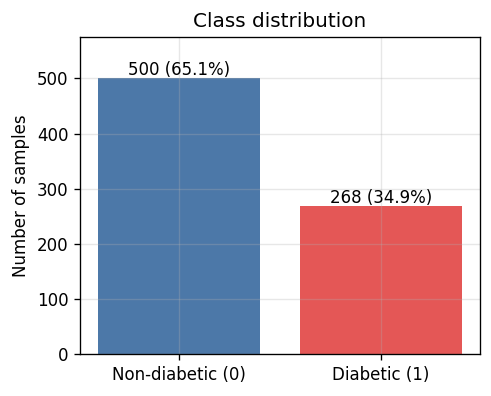

In [ ]:
ZERO_COLS = ['plas', 'pres', 'skin', 'insu', 'mass']   # 醫學上不可能為 0，視為缺失值

n = len(df)
vc = df['class'].value_counts().sort_index()
print(f"樣本數：{n}；特徵數：{df.shape[1]-1}")
print(f"陰性(0)：{vc[0]}（{vc[0]/n:.1%}）；陽性(1)：{vc[1]}（{vc[1]/n:.1%}）")

zero_tbl = pd.DataFrame({"0 值筆數": (df[ZERO_COLS] == 0).sum(),
                         "比例": ((df[ZERO_COLS] == 0).mean()*100).round(1).astype(str) + "%"})
print("\n被記為 0 的欄位（視為缺失值）：")
print(zero_tbl)

print("\n特徵敘述統計：")
print(df.drop(columns='class').describe().round(2).T[['mean','std','min','max']])

fig, ax = plt.subplots(figsize=(4.2, 3.4))
bars = ax.bar(['Non-diabetic (0)', 'Diabetic (1)'], vc.values, color=['#4C78A8', '#E45756'])
for b, v in zip(bars, vc.values):
    ax.text(b.get_x()+b.get_width()/2, v+6, f"{v} ({v/n:.1%})", ha='center')
ax.set_ylabel('Number of samples'); ax.set_title('Class distribution'); ax.set_ylim(0, vc.max()*1.15)
plt.tight_layout(); plt.savefig("outputs/fig_class_distribution.png"); plt.show()

## 3. 前處理與資料分割
0 → 缺失值（確定性規則，不含任何由資料估計的參數）；**補值與標準化皆放進 Pipeline，只用訓練集擬合**，避免資料洩漏。

In [ ]:
X = df.drop(columns='class').copy()
y = df['class'].copy()
X[ZERO_COLS] = X[ZERO_COLS].replace(0, np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"訓練集 {len(X_train)} 筆（陽性 {y_train.mean():.1%}）；測試集 {len(X_test)} 筆（陽性 {y_test.mean():.1%}）")

def make_models(cw):
    imp = lambda: SimpleImputer(strategy='median')
    return {
        'Logistic Regression': Pipeline([('imp', imp()), ('sc', StandardScaler()),
            ('clf', LogisticRegression(C=1.0, max_iter=1000, class_weight=cw, random_state=SEED))]),
        'Decision Tree': Pipeline([('imp', imp()),
            ('clf', DecisionTreeClassifier(max_depth=4, class_weight=cw, random_state=SEED))]),
        'Random Forest': Pipeline([('imp', imp()),
            ('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight=cw,
                                           random_state=SEED, n_jobs=-1))]),
    }
ROLE = {'Logistic Regression': 'Baseline 1', 'Decision Tree': 'Baseline 2', 'Random Forest': '提出方法'}

訓練集 614 筆（陽性 34.9%）；測試集 154 筆（陽性 35.1%）


## 4. 訓練與評估（E1 模型比較、E2 類別權重消融）

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, fitted = [], {}

for cw_name, cw in [('none', None), ('balanced', 'balanced')]:
    for name, pipe in make_models(cw).items():
        t0 = time.time(); pipe.fit(X_train, y_train); train_s = time.time() - t0
        pred = pipe.predict(X_test); proba = pipe.predict_proba(X_test)[:, 1]
        cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=['f1', 'roc_auc'])
        rows.append({
            'Model': name, 'Role': ROLE[name], 'class_weight': cw_name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred),
            'F1-score': f1_score(y_test, pred),
            'AUC-ROC': roc_auc_score(y_test, proba),
            'Train time (s)': train_s,
            'CV F1 (mean±std)': f"{cv['test_f1'].mean():.3f} ± {cv['test_f1'].std():.3f}",
            'CV AUC (mean±std)': f"{cv['test_roc_auc'].mean():.3f} ± {cv['test_roc_auc'].std():.3f}",
        })
        fitted[(name, cw_name)] = (pipe, pred, proba)

res = pd.DataFrame(rows)
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC-ROC']

print("=== 表 4-1／E1：未加權重，三個模型於測試集之效能 ===")
e1 = res[res.class_weight == 'none'].drop(columns='class_weight')
print(e1.round(3).to_string(index=False))

print("\n=== E2：class_weight='balanced' 前後比較（測試集）===")
e2 = res.pivot(index='Model', columns='class_weight', values=['Recall', 'F1-score', 'AUC-ROC', 'Precision'])
e2_out = pd.DataFrame({
    'Recall (none)': e2[('Recall','none')], 'Recall (balanced)': e2[('Recall','balanced')],
    'Δ Recall': e2[('Recall','balanced')] - e2[('Recall','none')],
    'Precision (none)': e2[('Precision','none')], 'Precision (balanced)': e2[('Precision','balanced')],
    'F1 (none)': e2[('F1-score','none')], 'F1 (balanced)': e2[('F1-score','balanced')],
    'AUC (none)': e2[('AUC-ROC','none')], 'AUC (balanced)': e2[('AUC-ROC','balanced')],
}).loc[list(ROLE)]
print(e2_out.round(3).to_string())

res.round(3).to_csv("outputs/results_all.csv", index=False)
e2_out.round(3).to_csv("outputs/results_E2_class_weight.csv")

=== 表 4-1／E1：未加權重，三個模型於測試集之效能 ===
              Model       Role  Accuracy  Precision  Recall  F1-score  AUC-ROC  Train time (s) CV F1 (mean±std) CV AUC (mean±std)
Logistic Regression Baseline 1     0.708      0.600   0.500     0.545    0.813           0.030    0.655 ± 0.024     0.843 ± 0.019
      Decision Tree Baseline 2     0.786      0.698   0.685     0.692    0.789           0.012    0.585 ± 0.060     0.788 ± 0.028
      Random Forest       提出方法     0.753      0.682   0.556     0.612    0.812           0.567    0.642 ± 0.014     0.827 ± 0.026

=== E2：class_weight='balanced' 前後比較（測試集）===
                     Recall (none)  Recall (balanced)  Δ Recall  Precision (none)  Precision (balanced)  F1 (none)  F1 (balanced)  AUC (none)  AUC (balanced)
Model                                                                                                                                                        
Logistic Regression          0.500              0.704     0.204             0.600    

## 5. 圖表（圖 4-1 混淆矩陣、圖 4-2 ROC 曲線）

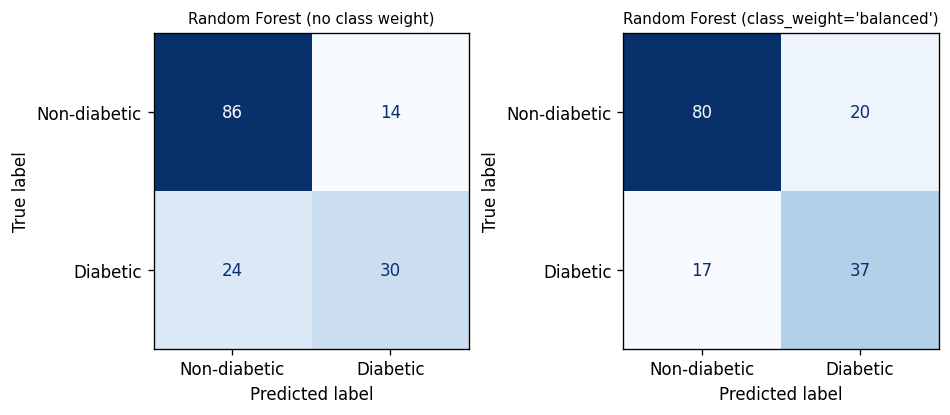

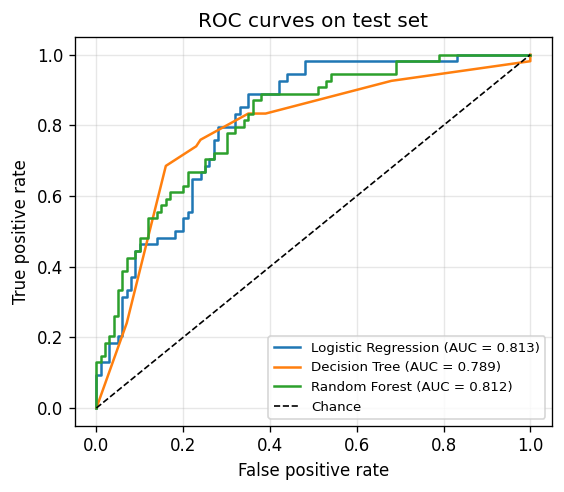

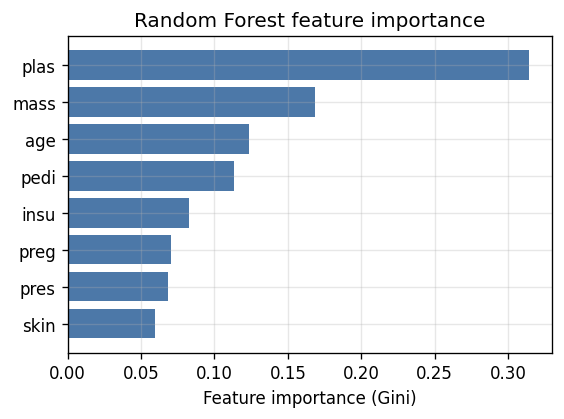

plas    0.314
mass    0.168
age     0.123
pedi    0.113
insu    0.082
preg    0.071
pres    0.068
skin    0.060
dtype: float64


In [ ]:
# 圖 4-1：提出方法（Random Forest）於 class_weight 前後的混淆矩陣
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, cw_name, title in zip(axes, ['none', 'balanced'],
                              ['Random Forest (no class weight)', "Random Forest (class_weight='balanced')"]):
    _, pred, _ = fitted[('Random Forest', cw_name)]
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Non-diabetic', 'Diabetic']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(title, fontsize=9); ax.grid(False)
plt.tight_layout(); plt.savefig("outputs/fig_confusion_matrix.png"); plt.show()

# 圖 4-2：三個模型的 ROC 曲線（未加權重）
fig, ax = plt.subplots(figsize=(4.8, 4.2))
for name in ROLE:
    _, _, proba = fitted[(name, 'none')]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC curves on test set'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig("outputs/fig_roc_curves.png"); plt.show()

# 圖 4-3：Random Forest 特徵重要性
rf = fitted[('Random Forest', 'none')][0].named_steps['clf']
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(4.8, 3.6))
ax.barh(imp.index, imp.values, color='#4C78A8')
ax.set_xlabel('Feature importance (Gini)'); ax.set_title('Random Forest feature importance')
plt.tight_layout(); plt.savefig("outputs/fig_feature_importance.png"); plt.show()
imp.sort_values(ascending=False).round(3).to_csv("outputs/feature_importance.csv")
print(imp.sort_values(ascending=False).round(3))

## 6. 錯誤分析（RQ3）：被漏判的糖尿病患者（False Negative）有何特徵？
以提出方法 Random Forest（未加權重）為對象，將「漏判者 FN」與「正確抓到者 TP」的特徵平均值（以原始、未補值資料計算）相比。

In [ ]:
_, pred, proba = fitted[('Random Forest', 'none')]
t = X_test.copy(); t['y'] = y_test.values; t['pred'] = pred; t['proba'] = proba
fn = t[(t.y == 1) & (t.pred == 0)]
tp = t[(t.y == 1) & (t.pred == 1)]
print(f"測試集陽性 {int(y_test.sum())} 人：正確抓到 TP = {len(tp)}、漏判 FN = {len(fn)}（漏判率 {len(fn)/y_test.sum():.1%}）")

feat = list(X.columns)
err = pd.DataFrame({'FN 平均': fn[feat].mean(), 'TP 平均': tp[feat].mean()})
err['差異 (FN−TP)'] = err['FN 平均'] - err['TP 平均']
err['FN 缺失比例'] = fn[feat].isna().mean()
err['TP 缺失比例'] = tp[feat].isna().mean()
print(err.round(2).to_string())
print(f"\nFN 的平均預測機率 = {fn['proba'].mean():.3f}；TP 的平均預測機率 = {tp['proba'].mean():.3f}")
err.round(3).to_csv("outputs/error_analysis_FN_vs_TP.csv")

測試集陽性 54 人：正確抓到 TP = 30、漏判 FN = 24（漏判率 44.4%）
       FN 平均   TP 平均  差異 (FN−TP)  FN 缺失比例  TP 缺失比例
preg    5.38    5.20        0.17     0.00     0.00
plas  117.75  157.80      -40.05     0.00     0.00
pres   70.61   78.96       -8.35     0.04     0.13
skin   32.54   31.80        0.74     0.46     0.33
insu  144.10  313.00     -168.90     0.58     0.63
mass   32.55   36.73       -4.18     0.00     0.00
pedi    0.45    0.62       -0.17     0.00     0.00
age    33.00   38.97       -5.97     0.00     0.00

FN 的平均預測機率 = 0.311；TP 的平均預測機率 = 0.703


## 7. 實驗環境（對應報告表 3-5）與打包下載

In [ ]:
import subprocess
try:
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'],
                         capture_output=True, text=True).stdout.strip() or '無 GPU（使用 CPU）'
except Exception:
    gpu = '無 GPU（使用 CPU）'
env = pd.DataFrame({'項目': ['執行平台', '硬體', '程式語言', '主要套件與版本', '隨機種子', '資料分割'],
    '規格': ['Google Colab', gpu, f"Python {platform.python_version()}",
             f"scikit-learn {sklearn.__version__}、pandas {pd.__version__}、numpy {np.__version__}",
             str(SEED), '訓練 80%／測試 20%，分層抽樣；訓練集內 5-fold 分層交叉驗證']})
print(env.to_string(index=False))
env.to_csv("outputs/environment.csv", index=False)

import shutil
shutil.make_archive("outputs", "zip", "outputs")
try:
    from google.colab import files
    files.download("outputs.zip")
except Exception:
    print("（非 Colab 環境，請自行取用 outputs.zip）")

     項目                                          規格
   執行平台                                Google Colab
     硬體                               無 GPU（使用 CPU）
   程式語言                              Python 3.13.18
主要套件與版本 scikit-learn 1.6.1、pandas 2.2.3、numpy 2.1.3
   隨機種子                                          42
   資料分割       訓練 80%／測試 20%，分層抽樣；訓練集內 5-fold 分層交叉驗證


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>